In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Ce code de web scraping a été exécuté localement sur une autre machine afin de collecter les données nécessaires au projet.
# Il est inclus ici uniquement à titre informatif et ne sera pas exécuté.
# Les données extraites ont déjà été sauvegardées et utilisées pour l'analyse.

import requests
from bs4 import BeautifulSoup
import pandas as pd
import time
import random
import os
from datetime import datetime

# Configuration
BASE_URL = "https://www.avito.ma/fr/maroc/voitures-%C3%A0_vendre?o={}"
OUTPUT_FILE = "avito_cars_data.csv"
MAX_PAGES = 2000
BATCH_SIZE = 5

# Rotation des user agents
USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Safari/15.1",
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:109.0) Gecko/20100101 Firefox/117.0",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/92.0.4515.159 Safari/537.36",
    "Mozilla/5.0 (iPhone; CPU iPhone OS 15_0 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/15.0 Mobile/15E148 Safari/604.1"
]

# Sélecteurs exacts basés sur le HTML fourni
SELECTORS = {
    # Sélecteur pour les titres des annonces (sur la page de liste)
    "listing_title": "p.sc-1x0vz2r-0.iHApav",

    # Sélecteur pour les liens des annonces
    "listing_links": "a.sc-1x0vz2r-0",

    # Sélecteurs pour les détails (page individuelle)
    "title": "h1.sc-1x0vz2r-0",
    "price": "p.sc-1x0vz2r-0.lnEFFR.sc-1veij0r-10.jdRkSM",

    # Sélecteurs pour les caractéristiques techniques
    "year": "div:has(> img[alt='Année-Modèle']) > div > span.sc-1x0vz2r-0.fjZBup",
    "brand": "div:has(> img[alt='Marque']) > div > span.sc-1x0vz2r-0.fjZBup",
    "model": "div:has(> img[alt='Modèle']) > div > span.sc-1x0vz2r-0.fjZBup",
    "mileage": "div:has(> img[alt='Kilométrage']) > div > span.sc-1x0vz2r-0.fjZBup",
    "fuel": "div:has(> img[alt='Type de carburant']) > div > span.sc-1x0vz2r-0.fjZBup",
    "gearbox": "div:has(> img[alt='Boite de vitesses']) > div > span.sc-1x0vz2r-0.fjZBup",
    "doors": "div:has(> img[alt='Nombre de portes']) > div > span.sc-1x0vz2r-0.fjZBup",
    "origin": "div:has(> img[alt='Origine']) > div > span.sc-1x0vz2r-0.fjZBup",
    "first_hand": "div:has(> img[alt='Première main']) > div > span.sc-1x0vz2r-0.fjZBup",
    "power": "div:has(> img[alt='Puissance fiscale']) > div > span.sc-1x0vz2r-0.fjZBup",
    "state": "div:has(> img[alt='État']) > div > span.sc-1x0vz2r-0.fjZBup",

    # Sélecteurs alternatifs plus génériques (en cas d'échec des premiers)
    "generic_specs": "div.sc-19cngu6-1"
}

def random_delay(min_sec=2, max_sec=6):
    """Attendre un temps aléatoire pour simuler un comportement humain"""
    delay = random.uniform(min_sec, max_sec)
    time.sleep(delay)

def get_headers():
    """Générer des en-têtes HTTP réalistes"""
    return {
        "User-Agent": random.choice(USER_AGENTS),
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
        "Accept-Language": "fr-FR,fr;q=0.9,en-US;q=0.8,en;q=0.7",
        "Accept-Encoding": "gzip, deflate, br",
        "Connection": "keep-alive",
        "Upgrade-Insecure-Requests": "1",
        "Cache-Control": "max-age=0",
        "Referer": "https://www.avito.ma/",
        "DNT": "1",
        "Sec-Fetch-Dest": "document",
        "Sec-Fetch-Mode": "navigate",
        "Sec-Fetch-Site": "same-origin"
    }

def load_existing_data():
    """Charger les données existantes si le fichier existe"""
    if os.path.exists(OUTPUT_FILE):
        print(f"Chargement des données existantes de {OUTPUT_FILE}")
        try:
            df = pd.read_csv(OUTPUT_FILE)
            existing_urls = set(df['url'].tolist())
            return df, existing_urls
        except Exception as e:
            print(f"Erreur lors de la lecture du fichier: {e}")

    # Créer un DataFrame vide avec les colonnes nécessaires
    columns = ['url', 'title', 'price', 'year', 'brand', 'model', 'mileage',
               'fuel', 'gearbox', 'doors', 'origin', 'first_hand', 'power', 'state']
    return pd.DataFrame(columns=columns), set()

def extract_car_details(soup, url):
    """Extraire les détails de l'annonce"""
    details = {'url': url}

    # Extraire le titre et le prix
    title_elem = soup.select_one(SELECTORS['title'])
    details['title'] = title_elem.text.strip() if title_elem else "N/A"

    price_elem = soup.select_one(SELECTORS['price'])
    details['price'] = price_elem.text.strip() if price_elem else "N/A"

    # Caractéristiques techniques
    for key in ['year', 'brand', 'model', 'mileage', 'fuel', 'gearbox',
                'doors', 'origin', 'first_hand', 'power', 'state']:
        elem = soup.select_one(SELECTORS[key])
        details[key] = elem.text.strip() if elem else "N/A"

    # Si certaines informations sont manquantes, essayer l'approche générique
    if 'N/A' in details.values():
        specs_divs = soup.select(SELECTORS['generic_specs'])
        for div in specs_divs:
            img = div.select_one('img')
            if img and img.has_attr('alt'):
                alt_text = img['alt']
                value_span = div.select_one('span.sc-1x0vz2r-0.fjZBup')
                if value_span:
                    value = value_span.text.strip()

                    if 'Année-Modèle' in alt_text and details['year'] == "N/A":
                        details['year'] = value
                    elif 'Marque' in alt_text and details['brand'] == "N/A":
                        details['brand'] = value
                    elif 'Modèle' in alt_text and details['model'] == "N/A":
                        details['model'] = value
                    elif 'Kilométrage' in alt_text and details['mileage'] == "N/A":
                        details['mileage'] = value
                    elif 'Type de carburant' in alt_text and details['fuel'] == "N/A":
                        details['fuel'] = value
                    elif 'Boite de vitesses' in alt_text and details['gearbox'] == "N/A":
                        details['gearbox'] = value
                    elif 'Nombre de portes' in alt_text and details['doors'] == "N/A":
                        details['doors'] = value
                    elif 'Origine' in alt_text and details['origin'] == "N/A":
                        details['origin'] = value
                    elif 'Première main' in alt_text and details['first_hand'] == "N/A":
                        details['first_hand'] = value
                    elif 'Puissance fiscale' in alt_text and details['power'] == "N/A":
                        details['power'] = value
                    elif 'État' in alt_text and details['state'] == "N/A":
                        details['state'] = value

    return details

def scrape_listing_page(page_num):
    """Scraper une page de résultats pour obtenir les liens des annonces"""
    url = BASE_URL.format(page_num)

    try:
        # Ajouter un délai aléatoire avant chaque requête
        random_delay(3, 8)

        response = requests.get(url, headers=get_headers(), timeout=15)

        if response.status_code != 200:
            print(f"⚠️ Erreur {response.status_code} sur la page {page_num}")
            return []

        soup = BeautifulSoup(response.text, 'html.parser')

        # Méthode 1: Trouver les liens directement
        links = soup.select(SELECTORS['listing_links'])

        urls = []
        for link in links:
            if link.has_attr('href') and '/voiture' in link['href']:
                full_url = link['href'] if link['href'].startswith('http') else f"https://www.avito.ma{link['href']}"
                urls.append(full_url)

        # Si on ne trouve pas d'annonces avec la méthode 1, essayer d'autres approches
        if not urls:
            # Méthode 2: Trouver tous les liens qui contiennent "voitures"
            all_links = soup.find_all('a')
            for link in all_links:
                if link.has_attr('href') and '/voiture' in link['href']:
                    full_url = link['href'] if link['href'].startswith('http') else f"https://www.avito.ma{link['href']}"
                    urls.append(full_url)

        print(f"📄 Page {page_num}: {len(urls)} annonces trouvées")

        # Si on est sur la première page et qu'on ne trouve pas d'annonces, enregistrer le HTML
        if page_num == 1 and not urls:
            debug_file = f"debug_page_{page_num}.html"
            with open(debug_file, "w", encoding="utf-8") as f:
                f.write(response.text)
            print(f"⚠️ Aucune annonce trouvée. HTML enregistré dans {debug_file}")

            # Vérifier si la page contient peut-être un message de détection de robot
            if "robot" in response.text.lower() or "captcha" in response.text.lower():
                print("⛔ Le site semble avoir détecté que vous êtes un robot!")
                print("💡 Essayez de changer d'adresse IP ou d'utiliser un VPN.")

        return urls

    except Exception as e:
        print(f"⚠️ Erreur sur la page {page_num}: {e}")
        # Attendre plus longtemps en cas d'erreur
        random_delay(10, 15)
        return []

def scrape_car_details(url, existing_urls):
    """Scraper les détails d'une annonce de voiture"""
    if url in existing_urls:
        print(f"📌 URL déjà scrapée: {url}")
        return None

    try:
        # Délai aléatoire pour simuler un comportement humain
        random_delay(5, 10)

        response = requests.get(url, headers=get_headers(), timeout=15)

        if response.status_code != 200:
            print(f"⚠️ Erreur {response.status_code} sur l'annonce: {url}")
            return None

        soup = BeautifulSoup(response.text, 'html.parser')

        # Extraire les détails
        details = extract_car_details(soup, url)

        print(f"✅ Annonce scrapée: {details.get('title', url)}")
        return details

    except Exception as e:
        print(f"⚠️ Erreur sur l'annonce {url}: {e}")
        return None

def save_data(data_frame):
    """Sauvegarder les données dans un fichier CSV"""
    try:
        data_frame.to_csv(OUTPUT_FILE, index=False)
        print(f"💾 Données sauvegardées: {len(data_frame)} annonces au total")

        # Créer une sauvegarde datée périodiquement
        if len(data_frame) % 500 == 0:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M")
            backup_file = f"avito_cars_backup_{timestamp}.csv"
            data_frame.to_csv(backup_file, index=False)
            print(f"📦 Sauvegarde créée: {backup_file}")

    except Exception as e:
        print(f"⚠️ Erreur lors de la sauvegarde: {e}")

def main():
    print("🚗 Démarrage du scraping des annonces Avito Voitures")

    # Charger les données existantes
    df, existing_urls = load_existing_data()

    # Scraper par lots pour éviter la détection
    for batch_start in range(1, MAX_PAGES + 1, BATCH_SIZE):
        batch_end = min(batch_start + BATCH_SIZE - 1, MAX_PAGES)
        print(f"\n📚 Traitement du lot de pages {batch_start} à {batch_end}")

        # Récupérer les URLs pour ce lot
        batch_urls = []
        for page in range(batch_start, batch_end + 1):
            urls = scrape_listing_page(page)
            batch_urls.extend(urls)

            # Pause après chaque page
            random_delay(5, 10)

            # Si on ne trouve pas d'annonces sur les 3 premières pages, il y a un problème
            if page <= 3 and not urls:
                print("⚠️ Aucune annonce trouvée dans les premières pages.")

        print(f"📋 {len(batch_urls)} URLs d'annonces trouvées dans ce lot")

        # Si aucune annonce n'est trouvée dans les premiers lots, augmenter le délai
        if not batch_urls and batch_start <= 5:
            print("⚠️ Augmentation du délai entre les requêtes...")
            random_delay(30, 60)  # Pause plus longue

        # Scraper les détails pour ce lot
        for url in batch_urls:
            if url not in existing_urls:
                details = scrape_car_details(url, existing_urls)
                if details:
                    # Ajouter les nouvelles données
                    df = pd.concat([df, pd.DataFrame([details])], ignore_index=True)
                    existing_urls.add(url)

                    # Sauvegarder régulièrement
                    if len(df) % 10 == 0:
                        save_data(df)

        # Pause entre les lots (varie selon la progression)
        if batch_start < 20:
            # Au début, pauses plus longues pour être moins suspect
            pause_time = random.randint(45, 90)
        else:
            pause_time = random.randint(30, 60)

        print(f"⏱️ Pause de {pause_time} secondes avant le prochain lot")
        time.sleep(pause_time)

        # Sauvegarder après chaque lot
        save_data(df)

        # Arrêter si on a atteint 50 000 annonces
        if len(df) >= 50000:
            print(f"🎯 Objectif atteint: {len(df)} annonces")
            break

    print(f"✨ Scraping terminé! {len(df)} annonces récupérées au total")

if __name__ == "__main__":
    try:
        main()
    except KeyboardInterrupt:
        print("\n⛔ Interruption par l'utilisateur")
    except Exception as e:
        print(f"❌ Erreur critique: {e}")

In [ ]:
# Importer les bibliothèques nécessaires
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Charger les données
file = "/content/drive/MyDrive/avito_cars_data.csv"
df = pd.read_csv(file,low_memory=False)
df.head()

,equipements,fuel,title,mileage,power,model,brand,description,gearbox,origin,price,boutique,first_hand,state,url,doors,year
0,NaN,Diesel,NaN,110 000 - 119 999,12 CV,X6,BMW,NaN,Automatique,WW au Maroc,NaN,NaN,Oui,Très bon,https://www.avito.ma/fr/casablanca_finance_cit...,5.0,2018
1,NaN,Diesel,NaN,140 000 - 149 999,6 CV,Grandland,Opel,NaN,Automatique,WW au Maroc,240 000 DH,NaN,Oui,Excellent,https://www.avito.ma/fr/aïn_chock/voitures_d'o...,5.0,2021
2,NaN,Diesel,NaN,50 000 - 54 999,8 CV,Coccinelle,Volkswagen,NaN,Automatique,WW au Maroc,NaN,NaN,Oui,Excellent,https://www.avito.ma/fr/hay_el_fath/voitures_d...,3.0,2020
3,NaN,Diesel,NaN,90 000 - 94 999,8 CV,A3,Audi,NaN,Automatique,Dédouanée,NaN,NaN,Oui,Excellent,https://www.avito.ma/fr/route_ain_chkaf/voitur...,5.0,2022
4,NaN,Diesel,NaN,90 000 - 94 999,6 CV,Focus,Ford,NaN,Manuelle,WW au Maroc,NaN,NaN,NaN,Excellent,https://www.avito.ma/fr/anfa/voitures_d'occasi...,5.0,2022


In [ ]:
# Afficher des statistiques descriptives sur les colonnes numériques
df.describe()

,doors
count,67349.000000
mean,4.870763
std,0.491707
min,3.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,5.000000


In [ ]:
# un résumé du DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77860 entries, 0 to 77859
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   equipements  20116 non-null  object 
 1   fuel         76154 non-null  object 
 2   title        29092 non-null  object 
 3   mileage      76074 non-null  object 
 4   power        76142 non-null  object 
 5   model        76090 non-null  object 
 6   brand        76068 non-null  object 
 7   description  27731 non-null  object 
 8   gearbox      76061 non-null  object 
 9   origin       67218 non-null  object 
 10  price        38729 non-null  object 
 11  boutique     27729 non-null  object 
 12  first_hand   65665 non-null  object 
 13  state        73106 non-null  object 
 14  url          77860 non-null  object 
 15  doors        67349 non-null  float64
 16  year         76099 non-null  object 
dtypes: float64(1), object(16)
memory usage: 10.1+ MB


In [ ]:
# Les dimensions du DataFrame
df.shape

(77860, 17)

In [ ]:
# La liste des noms de colonnes
df.columns.tolist()

['equipements',
 'fuel',
 'title',
 'mileage',
 'power',
 'model',
 'brand',
 'description',
 'gearbox',
 'origin',
 'price',
 'boutique',
 'first_hand',
 'state',
 'url',
 'doors',
 'year']

In [ ]:
# Supprimer les colonnes inutiles
df = df.drop(columns=['equipements', 'description', 'title', 'url', 'boutique'])
df

,fuel,mileage,power,model,brand,gearbox,origin,price,first_hand,state,doors,year
0,Diesel,110 000 - 119 999,12 CV,X6,BMW,Automatique,WW au Maroc,NaN,Oui,Très bon,5.0,2018
1,Diesel,140 000 - 149 999,6 CV,Grandland,Opel,Automatique,WW au Maroc,240 000 DH,Oui,Excellent,5.0,2021
2,Diesel,50 000 - 54 999,8 CV,Coccinelle,Volkswagen,Automatique,WW au Maroc,NaN,Oui,Excellent,3.0,2020
3,Diesel,90 000 - 94 999,8 CV,A3,Audi,Automatique,Dédouanée,NaN,Oui,Excellent,5.0,2022
4,Diesel,90 000 - 94 999,6 CV,Focus,Ford,Manuelle,WW au Maroc,NaN,NaN,Excellent,5.0,2022
...,...,...,...,...,...,...,...,...,...,...,...,...
77855,Diesel,160 000 - 169 999,7 CV,Partner,Peugeot,Manuelle,NaN,55000,Non,Très bon,3.0,2011
77856,Diesel,150 000 - 159 999,6 CV,Duster,Dacia,Automatique,WW au Maroc,151000,Non,Excellent,5.0,2021
77857,Diesel,Plus de 500 000,6 CV,Polo,Volkswagen,Manuelle,Dédouanée,54000,Non,Bon,5.0,2006
77858,Diesel,10 000 - 14 999,6 CV,Note,Nissan,Manuelle,Dédouanée,100000,Non,Excellent,5.0,2017


In [ ]:
# Nettoyer la colonne 'price'
df['price'] = (
    df['price']
    .astype(str)
    .str.replace(r"[^\d]", "", regex=True)  # Supprime tout sauf les chiffres
    .replace('', np.nan)                    # Remplace les chaînes vides par NaN
    .astype(float)
)
df = df[(df['price'] > 10000) & (df['price'] < 1000000)] # Supprime les valeurs aberrantes
df

,fuel,mileage,power,model,brand,gearbox,origin,price,first_hand,state,doors,year
1,Diesel,140 000 - 149 999,6 CV,Grandland,Opel,Automatique,WW au Maroc,240000.0,Oui,Excellent,5.0,2021
5,Diesel,150 000 - 159 999,9 CV,Ranger,Ford,Manuelle,WW au Maroc,195000.0,Oui,Excellent,5.0,2014
8,Diesel,300 000 - 349 999,8 CV,Golf 4,Volkswagen,Manuelle,Dédouanée,59000.0,Non,Très bon,5.0,2003
9,Diesel,150 000 - 159 999,12 CV,Cayenne,Porsche,Automatique,WW au Maroc,380000.0,NaN,Très bon,5.0,2017
10,Hybride,15 000 - 19 999,7 CV,Corolla,Toyota,Automatique,WW au Maroc,280000.0,Oui,Excellent,5.0,2024
...,...,...,...,...,...,...,...,...,...,...,...,...
77855,Diesel,160 000 - 169 999,7 CV,Partner,Peugeot,Manuelle,NaN,55000.0,Non,Très bon,3.0,2011
77856,Diesel,150 000 - 159 999,6 CV,Duster,Dacia,Automatique,WW au Maroc,151000.0,Non,Excellent,5.0,2021
77857,Diesel,Plus de 500 000,6 CV,Polo,Volkswagen,Manuelle,Dédouanée,54000.0,Non,Bon,5.0,2006
77858,Diesel,10 000 - 14 999,6 CV,Note,Nissan,Manuelle,Dédouanée,100000.0,Non,Excellent,5.0,2017


In [ ]:
# Nettoyer la colonne 'power'
df.loc[:, 'power'] = df['power'].str.replace('CV', '').str.strip()
df.loc[:, 'power'] = pd.to_numeric(df['power'], errors='coerce')

In [ ]:
# Nettoyer la colonne 'mileage'
def extract_mileage(val):
    if isinstance(val, str) and '-' in val:
        numbers = re.findall(r'\d+', val.replace(' ', ''))
        if len(numbers) == 2:
            return (int(numbers[0]) + int(numbers[1])) // 2
    elif isinstance(val, str):
        return int(re.sub(r'\D', '', val))
    return np.nan
df.loc[:, 'mileage'] = df['mileage'].apply(extract_mileage)

In [ ]:
# Convertir 'year' en numérique
df.loc[:, 'year'] = pd.to_numeric(df['year'], errors='coerce')
df = df[(df['year'] >= 1980) & (df['year'] <= 2024)]

In [ ]:
# Supprimer les lignes avec des valeurs manquantes essentielles
df = df.dropna(subset=['brand', 'model', 'mileage', 'power', 'year', 'price'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 38058 entries, 1 to 77859
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fuel        38058 non-null  object 
 1   mileage     38058 non-null  object 
 2   power       38058 non-null  object 
 3   model       38058 non-null  object 
 4   brand       38058 non-null  object 
 5   gearbox     38054 non-null  object 
 6   origin      33886 non-null  object 
 7   price       38058 non-null  float64
 8   first_hand  33180 non-null  object 
 9   state       36641 non-null  object 
 10  doors       34081 non-null  float64
 11  year        38058 non-null  object 
dtypes: float64(2), object(10)
memory usage: 3.8+ MB


In [ ]:
# Remplir certaines valeurs manquantes avec le mode
for col in ['gearbox', 'doors', 'origin', 'first_hand', 'state']:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
# Afficher le nombre de valeurs manquantes pour chaque colonne du DataFrame
df.isnull().sum()

,0
fuel,0
mileage,0
power,0
model,0
brand,0
gearbox,0
origin,0
price,0
first_hand,0
state,0


In [ ]:
# Supprimer les doublons
df.drop_duplicates(inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 34377 entries, 1 to 77859
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fuel        34377 non-null  object 
 1   mileage     34377 non-null  object 
 2   power       34377 non-null  object 
 3   model       34377 non-null  object 
 4   brand       34377 non-null  object 
 5   gearbox     34377 non-null  object 
 6   origin      34377 non-null  object 
 7   price       34377 non-null  float64
 8   first_hand  34377 non-null  object 
 9   state       34377 non-null  object 
 10  doors       34377 non-null  float64
 11  year        34377 non-null  object 
dtypes: float64(2), object(10)
memory usage: 3.4+ MB


📊 1. Price statistics:
 count     34377.000000
mean     154930.689182
std      118651.800792
min       10200.000000
25%       75000.000000
50%      126000.000000
75%      192000.000000
max      999999.000000
Name: price, dtype: float64


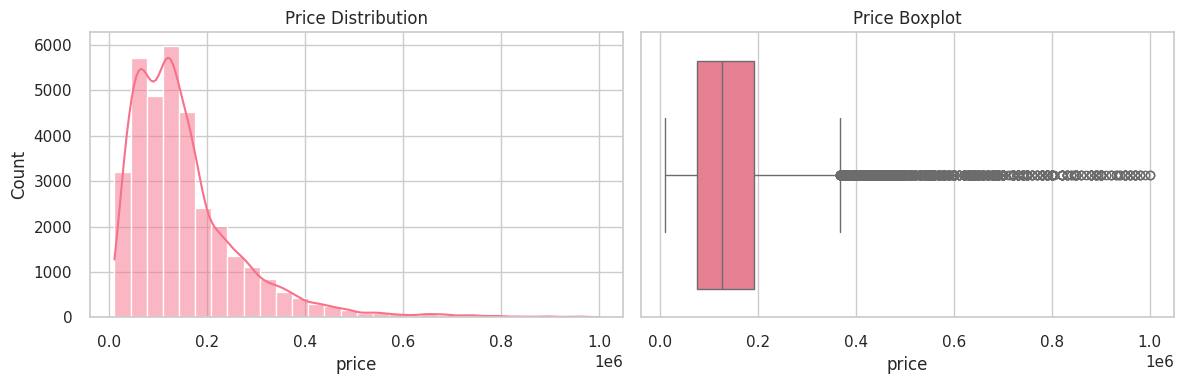


🏷 2. Average price by brand (Top 10):
 model
California        930000.000000
LS                910000.000000
X7                890000.000000
EQE               846666.666667
Série 8           800000.000000
Q8                750475.000000
Classe GLS        750000.000000
Classe GL         700000.000000
Classe G          646250.000000
Continental GT    625000.000000
Name: price, dtype: float64


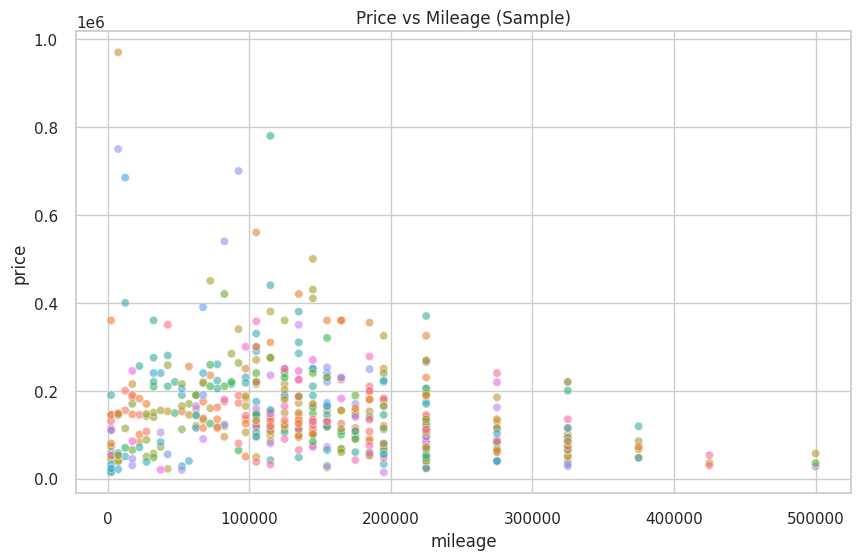

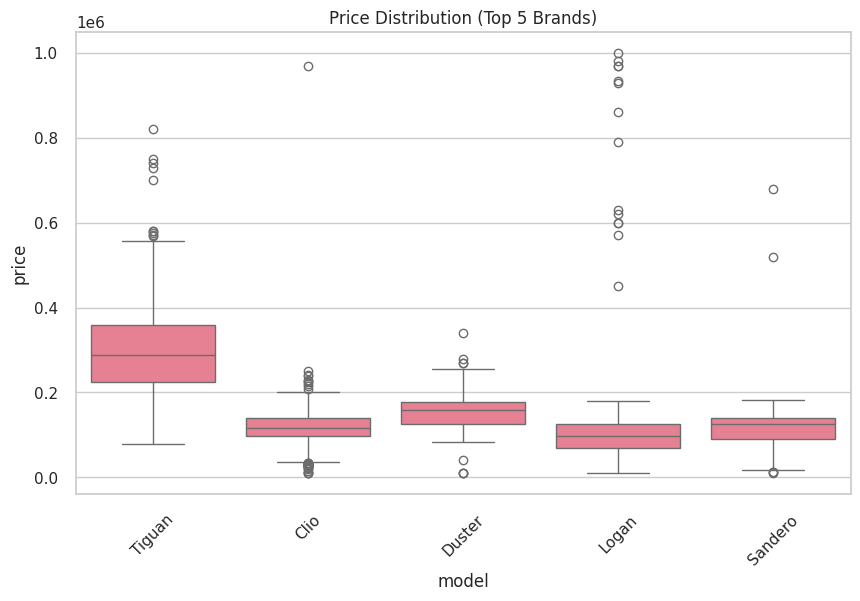


🔥 3. Top 10 most frequent models:
 model
Clio       1227
Logan      1006
Tiguan      738
Sandero     687
Duster      660
Megane      596
220         592
Dokker      559
Kangoo      556
208         505
Name: count, dtype: int64


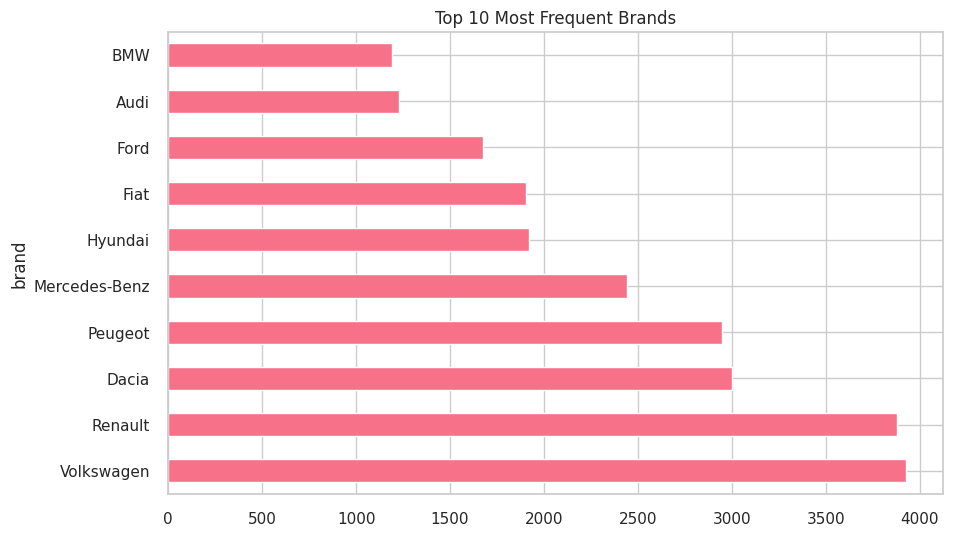


🔗 Correlation matrix:
             price      year   mileage
price    1.000000  0.549352 -0.218847
year     0.549352  1.000000 -0.334197
mileage -0.218847 -0.334197  1.000000


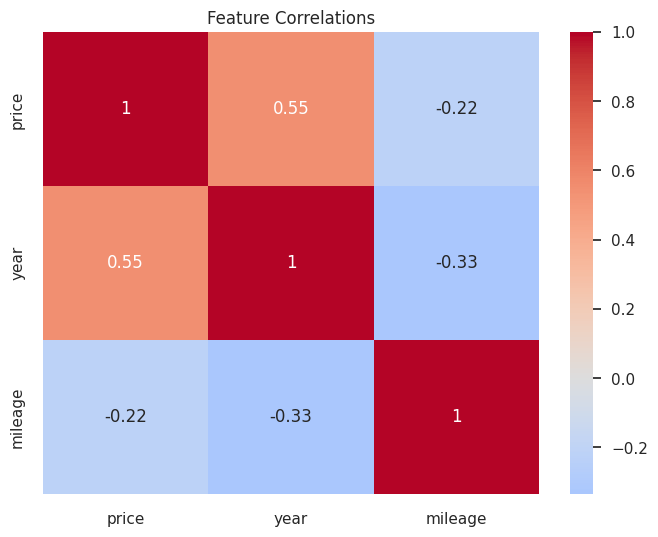


📌 KEY INSIGHTS:
- Median price: 126,000 DH
- Most expensive brand: California (930,000 DH)
- Most popular model: 'Clio'
- Price drops by 0.22% per km
- Newer cars (year) are 55% more expensive


In [ ]:
# Analyse Des Tendances Du Marché

# Configuration spécifique pour cette analyse
plt.style.use('seaborn-v0_8')
sns.set_theme(style="whitegrid", palette="husl")
%matplotlib inline

# Statistiques de base sur les prix

print("📊 1. Price statistics:\n", df['price'].describe())
# Distribution des prix
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=30)
plt.title("Price Distribution")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['price'])
plt.title("Price Boxplot")
plt.tight_layout()
plt.show()

# Prix moyen par modèle (top 10)
price_by_brand = df.groupby('model')['price'].mean().sort_values(ascending=False)
print("\n🏷 2. Average price by brand (Top 10):\n", price_by_brand.head(10))

# Price vs Mileage
plt.figure(figsize=(10, 6))
sns.scatterplot(x='mileage', y='price', hue='model',
                data=df.sample(500), alpha=0.6, legend=False)
plt.title("Price vs Mileage (Sample)")
plt.show()

# Top 5 brands analysis
top_5_brands = df['model'].value_counts().head(5).index
df_top = df[df['model'].isin(top_5_brands)]

plt.figure(figsize=(10, 6))
sns.boxplot(x='model', y='price', data=df_top)
plt.title("Price Distribution (Top 5 Brands)")
plt.xticks(rotation=45)
plt.show()

# Modèles les plus fréquents
print("\n🔥 3. Top 10 most frequent models:\n", df['model'].value_counts().head(10))
# Top 10 marques les plus fréquentes
plt.figure(figsize=(10, 6))
df['brand'].value_counts().head(10).plot(kind='barh')
plt.title("Top 10 Most Frequent Brands")
plt.show()

# Correlation analysis
corr_matrix = df[['price', 'year', 'mileage']].corr()
print("\n🔗 Correlation matrix:\n", corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title("Feature Correlations")
plt.show()

# Auto-summary
print("\n📌 KEY INSIGHTS:")
print(f"- Median price: {df['price'].median():,.0f} DH")
print(f"- Most expensive brand: {price_by_brand.idxmax()} ({price_by_brand.max():,.0f} DH)")
print(f"- Most popular model: '{df['model'].value_counts().idxmax()}'")
print(f"- Price drops by {-corr_matrix.loc['price', 'mileage']:.2f}% per km")
print(f"- Newer cars (year) are {corr_matrix.loc['price', 'year']*100:.0f}% more expensive")

In [ ]:
# Encodage des variables catégorielles
label_encoders = {}
for col in ['brand', 'model', 'fuel', 'gearbox', 'origin', 'state', 'first_hand']:
    df[col] = df[col].astype(str)
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

In [ ]:
# Normalisation des données numériques
scaler = StandardScaler()
df[['mileage', 'power', 'year']] = scaler.fit_transform(df[['mileage', 'power', 'year']])

In [ ]:
# Sauvegarder le dataset nettoyé
df.to_csv('clean_avito_data.csv', index=False)

print("✅ Dataset nettoyé et sauvegardé sous 'clean_avito_data.csv'")
df.head()

✅ Dataset nettoyé et sauvegardé sous 'clean_avito_data.csv'


,fuel,mileage,power,model,brand,gearbox,origin,price,first_hand,state,doors,year
1,0,0.043226,-0.646195,355,57,0,3,240000.0,1,3,5.0,0.939701
5,0,0.145636,0.666807,551,27,1,3,195000.0,1,3,5.0,0.072473
8,0,1.886613,0.229140,342,73,1,0,59000.0,0,6,5.0,-1.290312
9,0,0.145636,1.979808,192,60,0,3,380000.0,0,6,5.0,0.444142
10,3,-1.262507,-0.208527,239,72,0,3,280000.0,1,3,5.0,1.311369


In [ ]:
# Pour un meilleur affichage
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

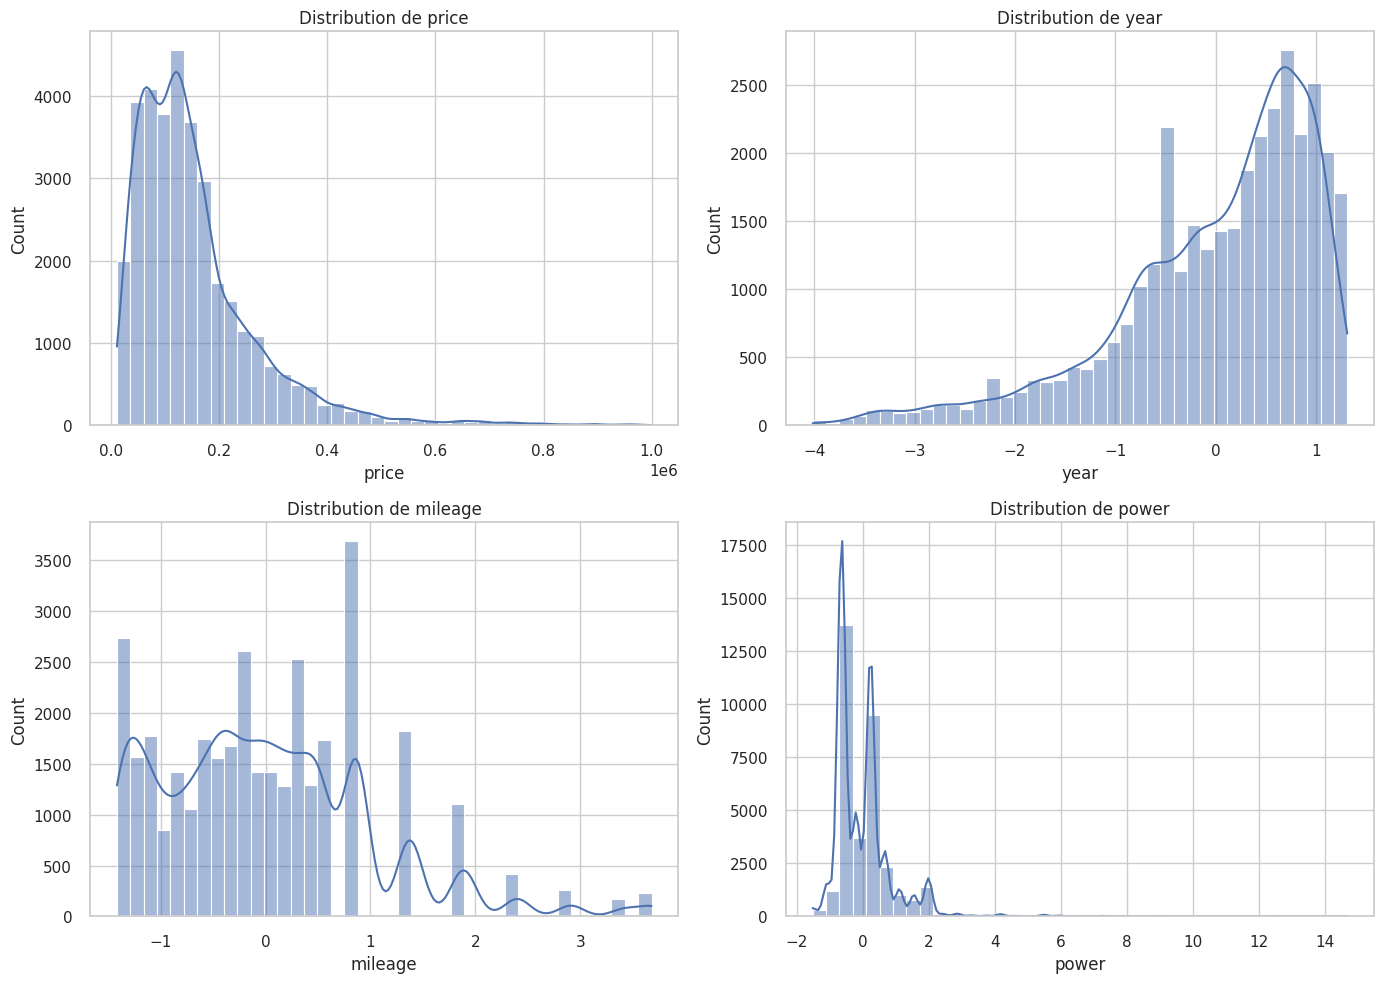

In [ ]:
# Charger les données nettoyées
df = pd.read_csv('clean_avito_data.csv')

# Histogrammes
numerical_cols = ['price', 'year', 'mileage', 'power']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, col in enumerate(numerical_cols):
    row, col_idx = divmod(i, 2)
    sns.histplot(df[col], kde=True, bins=40, ax=axes[row, col_idx])
    axes[row, col_idx].set_title(f"Distribution de {col}")

plt.tight_layout()
plt.show()

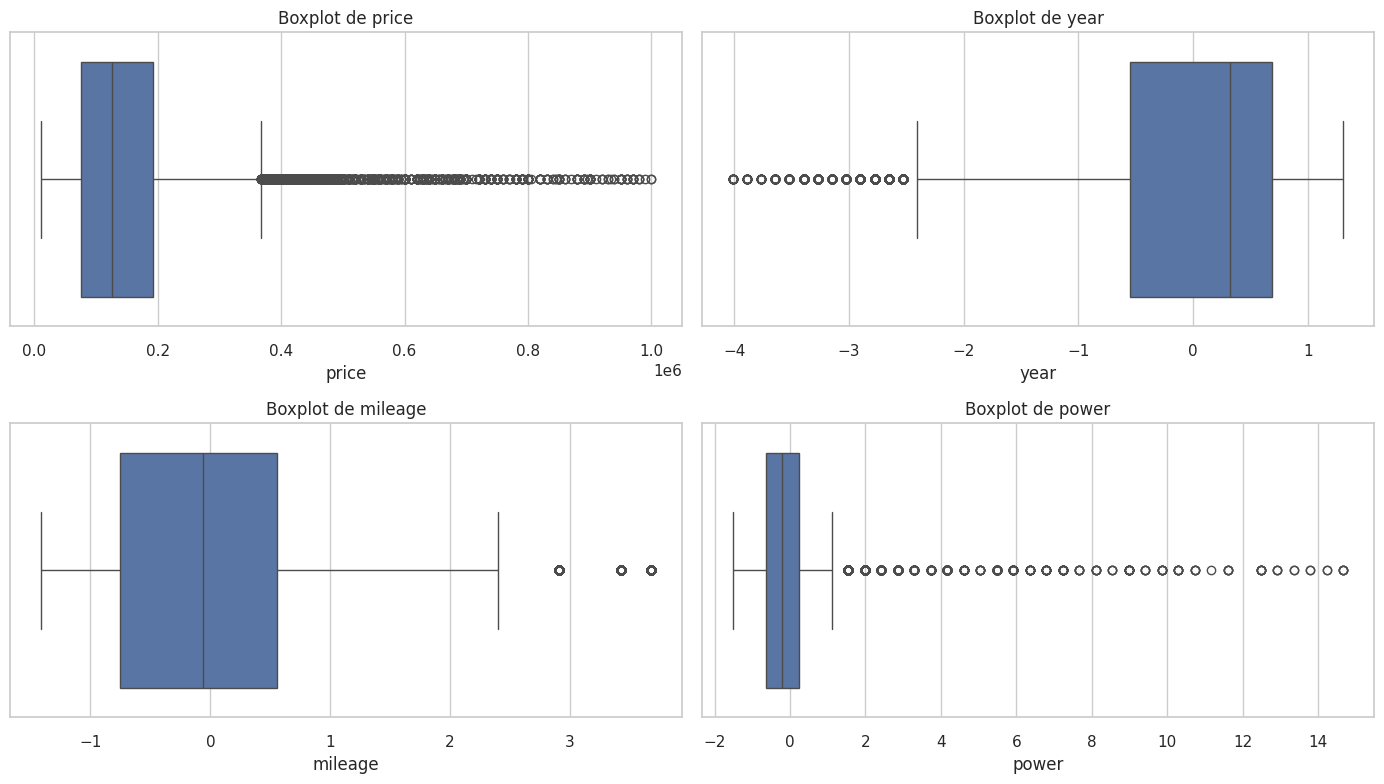

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Afficher les boxplots
for i, col in enumerate(numerical_cols):
    row, col_idx = divmod(i, 2)
    sns.boxplot(x=df[col], ax=axes[row, col_idx])
    axes[row, col_idx].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

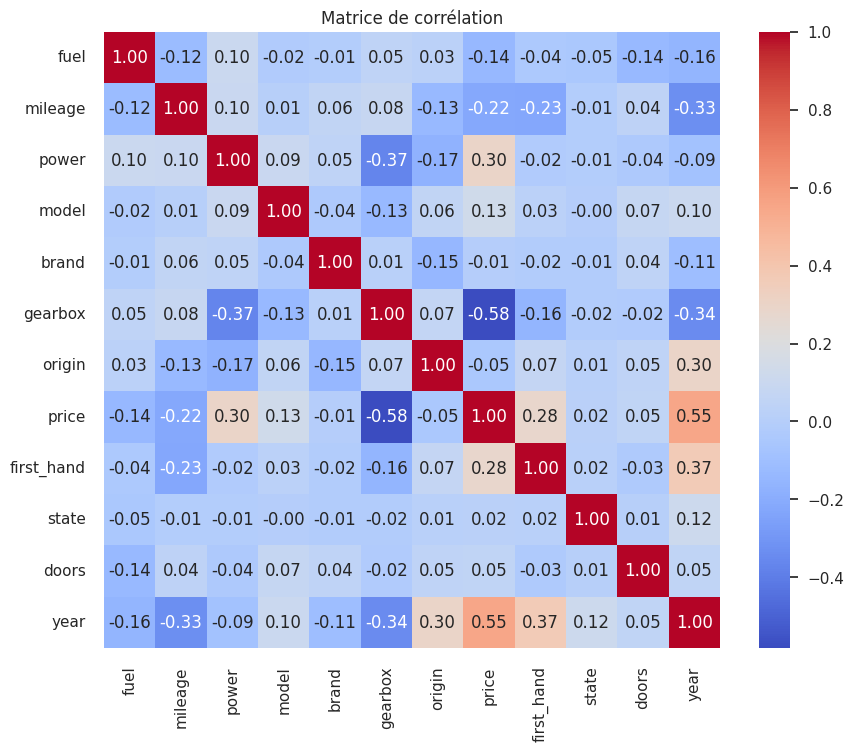

In [ ]:
# Calcul de la corrélation
corr_matrix = df.corr(numeric_only=True)

# Affichage de la heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title("Matrice de corrélation")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import seaborn as sns
import matplotlib.pyplot as plt
import lightgbm as lgb
from catboost import CatBoostRegressor

In [ ]:
# Séparation des données
X = df.drop(columns=['price'])
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Définition d'un dictionnaire contenant plusieurs modèles de régression
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
        ),
    'XGBoost': XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
        ),
    'LightGBM': lgb.LGBMRegressor(
        n_estimators=1000,
        learning_rate=0.1,
        verbosity=-1,
        force_col_wise=True,
        random_state=42
    ),
    'CatBoost': CatBoostRegressor(
        iterations=1000,
        learning_rate=0.1,
        depth=6,
        random_state=42,
        verbose=0
    )
}

# Dictionnaire pour stocker les résultats de performance de chaque modèle
results = {}

# Boucle sur chaque modèle pour l'entraîner et évaluer ses performances
for name, model in models.items():
    model.fit(X_train, y_train)       # Entraînement du modèle
    y_pred = model.predict(X_test)    # Prédictions sur l'ensemble de test

    # Calcul des scores de performance
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results[name] = {'R2': r2, 'RMSE': rmse}

    # Affichage des performances
    print(f"📌 {name} — R2: {r2:.4f}, RMSE: {rmse:.2f}")

📌 LinearRegression — R2: 0.5541, RMSE: 79602.77
📌 RandomForest — R2: 0.8156, RMSE: 51198.73
📌 XGBoost — R2: 0.8398, RMSE: 47711.87
📌 LightGBM — R2: 0.8470, RMSE: 46627.31
📌 CatBoost — R2: 0.8480, RMSE: 46480.10


In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Définir le modèle
xgb_model = XGBRegressor(random_state=42)

# Définir la grille d'hyperparamètres
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1]
}

# Définir GridSearchCV
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid,
                           cv=3, scoring='r2', n_jobs=-1, verbose=1)

# Lancer la recherche
grid_search.fit(X_train, y_train)

# Afficher les meilleurs paramètres
print("✅ Meilleurs hyperparamètres trouvés :", grid_search.best_params_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
✅ Meilleurs hyperparamètres trouvés : {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.8}


In [ ]:
# Meilleur modèle
best_model = grid_search.best_estimator_

# Prédictions sur les données de test
y_pred_best = best_model.predict(X_test)

# Évaluer les performances
r2_best = r2_score(y_test, y_pred_best)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best))

print(f"📈 XGBoost optimisé — R2: {r2_best:.4f}, RMSE: {rmse_best:.2f}")

📈 XGBoost optimisé — R2: 0.8460, RMSE: 46785.27


In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import make_scorer, r2_score
import numpy as np

# Définir la stratégie de validation croisée
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Utiliser le modèle optimisé trouvé avec GridSearch
xgb_best = grid_search.best_estimator_

# Appliquer la validation croisée (sur l'ensemble du jeu d'entraînement)
r2_scores = cross_val_score(xgb_best, X_train, y_train, cv=kf, scoring='r2')

# Affichage des scores
print("📊 Scores R² pour chaque fold :", r2_scores)
print(f"✅ Moyenne R² : {np.mean(r2_scores):.4f}")
print(f"📉 Écart-type R² : {np.std(r2_scores):.4f}")

📊 Scores R² pour chaque fold : [0.80191879 0.84822574 0.8033463  0.82795627 0.84106315]
✅ Moyenne R² : 0.8245
📉 Écart-type R² : 0.0190


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, r2_score
import numpy as np

# Configuration d'optimisation pour LightGBM
lgbm_params = {
    'n_estimators': [800, 1000],
    'max_depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [31, 63]
}

# Configuration d'optimisation pour CatBoost
catboost_params = {
    'iterations': [800, 1000],
    'depth': [5, 7],
    'learning_rate': [0.05, 0.1],
    'l2_leaf_reg': [1, 5]
}

# Scorer personnalisé
scorer = make_scorer(r2_score, greater_is_better=True)

# Optimisation LightGBM
lgbm_grid = GridSearchCV(
    estimator=lgb.LGBMRegressor(verbosity=-1, force_col_wise=True, random_state=42),
    param_grid=lgbm_params,
    cv=3,
    scoring=scorer,
    n_jobs=-1,
    verbose=1
)
lgbm_grid.fit(X_train, y_train)

# Optimisation CatBoost
catboost_grid = GridSearchCV(
    estimator=CatBoostRegressor(verbose=0, random_state=42),
    param_grid=catboost_params,
    cv=3,
    scoring=scorer,
    n_jobs=-1,
    verbose=1
)
catboost_grid.fit(X_train, y_train)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Fitting 3 folds for each of 16 candidates, totalling 48 fits


GridSearchCV(cv=3,
             estimator=<catboost.core.CatBoostRegressor object at 0x7e90c1f225d0>,
             n_jobs=-1,
             param_grid={'depth': [5, 7], 'iterations': [800, 1000],
                         'l2_leaf_reg': [1, 5], 'learning_rate': [0.05, 0.1]},
             scoring=make_scorer(r2_score, response_method='predict'),
             verbose=1)

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(model, X, y):
    r2_scores = cross_val_score(model, X, y, cv=kf, scoring='r2')
    rmse_scores = cross_val_score(model, X, y, cv=kf,
                                scoring='neg_root_mean_squared_error')

    print(f"🔍 {model.__class__.__name__}")
    print(f"R² moyen: {np.mean(r2_scores):.4f} (±{np.std(r2_scores):.4f})")
    print(f"RMSE moyen: {-np.mean(rmse_scores):.2f} (±{np.std(rmse_scores):.2f})\n")
    return model

# Évaluation des modèles optimisés
best_lgbm = lgbm_grid.best_estimator_
best_catboost = catboost_grid.best_estimator_

print("⚙️ Résultats après optimisation:")
evaluate_model(best_lgbm, X_train, y_train)
evaluate_model(best_catboost, X_train, y_train)

⚙️ Résultats après optimisation:
🔍 LGBMRegressor
R² moyen: 0.8300 (±0.0195)
RMSE moyen: 48771.98 (±2732.04)

🔍 CatBoostRegressor
R² moyen: 0.8292 (±0.0206)
RMSE moyen: 48882.32 (±2871.36)



In [ ]:
def test_evaluation(model, X_train, y_train, X_test, y_test):
    # Entraînement du modèle
    model.fit(X_train, y_train)

    # Prédictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calcul des métriques
    r2_train = r2_score(y_train, y_train_pred)
    r2_test = r2_score(y_test, y_test_pred)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
    rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

    # Affichage des résultats
    print(f"📊 Performance du modèle {model.__class__.__name__}")
    print("┌──────────────────┬────────────┬────────────┐")
    print("│ Métrique         │ Train      │ Test       │")
    print("├──────────────────┼────────────┼────────────┤")
    print(f"│ R²               │ {r2_train:.4f}    │ {r2_test:.4f}    │")
    print(f"│ RMSE             │ {rmse_train:>8.2f}  │ {rmse_test:>8.2f}  │")
    print("└──────────────────┴────────────┴────────────┘\n")

    return model

# Utilisation
final_lgbm = test_evaluation(best_lgbm, X_train, y_train, X_test, y_test)
final_catboost = test_evaluation(best_catboost, X_train, y_train, X_test, y_test)

📊 Performance du modèle LGBMRegressor
┌──────────────────┬────────────┬────────────┐
│ Métrique         │ Train      │ Test       │
├──────────────────┼────────────┼────────────┤
│ R²               │ 0.8850    │ 0.8501    │
│ RMSE             │ 40192.91  │ 46151.98  │
└──────────────────┴────────────┴────────────┘

📊 Performance du modèle CatBoostRegressor
┌──────────────────┬────────────┬────────────┐
│ Métrique         │ Train      │ Test       │
├──────────────────┼────────────┼────────────┤
│ R²               │ 0.8852    │ 0.8488    │
│ RMSE             │ 40158.93  │ 46349.31  │
└──────────────────┴────────────┴────────────┘



In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

# Dictionnaire des modèles optimisés
models = {
    'XGBoost': best_model,      # modèle XGBoost optimisé
    'LightGBM': best_lgbm,      # modèle LightGBM optimisé
    'CatBoost': best_catboost   # modèle CatBoost optimisé
}

# Calcul des métriques
results = []
for name, model in models.items():
    # Prédictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calcul des métriques
    results.append({
        'Modèle': name,
        'R² Train': r2_score(y_train, y_train_pred),
        'R² Test': r2_score(y_test, y_test_pred),
        'RMSE Train': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'RMSE Test': np.sqrt(mean_squared_error(y_test, y_test_pred))
    })

# Création du DataFrame
df_results = pd.DataFrame(results)

# Affichage formaté
print("🔍 Comparaison des modèles optimisés (Train vs Test)")
print(df_results.round(4))

🔍 Comparaison des modèles optimisés (Train vs Test)
     Modèle  R² Train  R² Test  RMSE Train   RMSE Test
0   XGBoost    0.8876   0.8460  39738.1967  46785.2709
1  LightGBM    0.8850   0.8501  40192.9085  46151.9846
2  CatBoost    0.8852   0.8488  40158.9323  46349.3115


In [ ]:
import joblib
# 1. Sauvegarder le modèle entraîné
joblib.dump(best_lgbm, 'best_lgb_model.pkl')

# 2. Sauvegarder les LabelEncoders
joblib.dump(label_encoders, 'label_encoders.pkl')

# 3. Sauvegarder le scaler
joblib.dump(scaler, 'scaler.pkl')

# 4. Sauvegarder la liste exacte des colonnes utilisées pour l'entraînement
joblib.dump(X.columns.tolist(), 'X_columns.pkl')

print("✅ Tous les objets ont été sauvegardés avec succès.")

✅ Tous les objets ont été sauvegardés avec succès.
